In [16]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mahletadane/gpac-data/GPAC.txt


In [17]:
%%writefile /kaggle/working/preprocess_lib.py
"""Shared text rules for GPAC preprocessing, predict_next() and the app.
Everything must import these functions. Never re-implement them elsewhere."""
import hashlib
import re
import unicodedata

RULES_VERSION = "preprocessing-v2"

# ------------------------------------------------------------------ settings
MERGE_FOURTH_ORDER_HA = True   # True also merges ሃ ሓ ኃ -> ሀ (like ዓ ኣ -> አ). Team decision.
NUM = "<NUM>"
SAMPLE_SEED = 42                # picks which sentences go into the sample
SPLIT_SEED = 7                  # decides train / dev / test for every sentence

# Sentence ends: ፡፡  ::  ።  ?  !  ፧   (never '.')
SPLIT_RE = re.compile(r"(?:፡፡|::|[።?!፧])+")

# ------------------------------------------------------------------ spelling variants
_ORDERS = ["A", "U", "I", "AA", "EE", "E", "O"]   # the 7 vowel orders of an Ethiopic letter


def _syl(prefix, order):
    """Look a syllable up by its Unicode name, so a wrong name fails loudly."""
    return unicodedata.lookup(f"ETHIOPIC SYLLABLE {prefix}{order}")


def _build_variant_table():
    table = {}
    # variant family -> standard family, all 7 orders of each
    for src, dst in [("HH", "H"), ("X", "H"),        # ሐ ኀ -> ሀ
                     ("SZ", "S"),                    # ሠ   -> ሰ
                     ("PHARYNGEAL ", "GLOTTAL "),    # ዐ   -> አ
                     ("TZ", "TS")]:                  # ፀ   -> ጸ
        for o in _ORDERS:
            table[ord(_syl(src, o))] = _syl(dst, o)
    # 4th order merged into the 1st order as well: ዓ ኣ -> አ
    a = _syl("GLOTTAL ", "A")
    table[ord(_syl("PHARYNGEAL ", "AA"))] = a
    table[ord(_syl("GLOTTAL ", "AA"))] = a
    if MERGE_FOURTH_ORDER_HA:
        ha = _syl("H", "A")
        for fam in ("H", "HH", "X"):
            table[ord(_syl(fam, "AA"))] = ha         # ሃ ሓ ኃ -> ሀ
    return table


_VARIANTS = _build_variant_table()


def normalize(text):
    """Spelling normalization only: Unicode NFC + merging of letter variants."""
    return unicodedata.normalize("NFC", text).translate(_VARIANTS)


# ------------------------------------------------------------------ tokenizer
_LETTER = r"[^\W\d_\u1369-\u137C]"                    # letters (not digits, not Ethiopic numerals)
_DIGITS = r"[0-9\u1369-\u137C]"                       # Arabic digits + Ethiopic numerals
_NUMBER = rf"<NUM>|{_DIGITS}+(?:[.,]{_DIGITS}+)*"     # accepts <NUM> itself, so tokenize() is idempotent
TOKEN_RE = re.compile(rf"({_LETTER}*)({_NUMBER})({_LETTER}*)|({_LETTER}+)")


def tokenize(text):
    """Raw text of ONE sentence -> list of tokens.
    Punctuation is dropped, numbers become <NUM>, and letters attached to a number are kept
    (19ኛ -> <NUM>ኛ, በ1980 -> በ<NUM>). The same number twice in a row is kept once."""
    tokens = []
    prev_number = None                                # raw text of the previous token if it was a bare number
    for m in TOKEN_RE.finditer(normalize(text)):
        pre, number, suf, word = m.groups()
        if word is not None:
            tokens.append(word)
            prev_number = None
            continue
        bare = not pre and not suf
        if bare and number != NUM and number == prev_number:
            continue                                  # identical consecutive number: collapse
        tokens.append(f"{pre}{NUM}{suf}")
        prev_number = number if bare else None
    return tokens


def split_sentences(text):
    """Split on the sentence delimiters and drop empty pieces."""
    return [p.strip() for p in SPLIT_RE.split(text) if p.strip()]


# ------------------------------------------------------------------ deterministic split
def sentence_key(tokens):
    """What identifies a sentence: its normalized tokens joined by spaces."""
    return " ".join(tokens)


def hash64(seed, text):
    """Stable 64-bit hash: the same on every machine and every run (Python's hash() is not)."""
    digest = hashlib.blake2b(f"{seed}|{text}".encode("utf-8"), digest_size=8).digest()
    return int.from_bytes(digest, "big")


def split_of_hash(h):
    r = h / 2**64
    return "train" if r < 0.8 else ("dev" if r < 0.9 else "test")


def assign_split(key):
    """80/10/10. The same key always gets the same split."""
    return split_of_hash(hash64(SPLIT_SEED, key))

Overwriting /kaggle/working/preprocess_lib.py


In [18]:
import sys
sys.path.insert(0, "/kaggle/working")
import importlib
from collections import Counter
import preprocess_lib
importlib.reload(preprocess_lib)
from preprocess_lib import (normalize, tokenize, split_sentences, sentence_key,
                            assign_split, hash64, SPLIT_SEED)

# ---- 1. NFC and letter variants ----
assert normalize("e\u0301") == "\u00e9"                       # NFC composes
for src, dst in [("ሐ", "ሀ"), ("ኀ", "ሀ"), ("ሠ", "ሰ"), ("ዐ", "አ"), ("ፀ", "ጸ"),
                 ("ዓ", "አ"), ("ኣ", "አ")]:
    assert normalize(src) == dst, (src, dst)
for src, dst in [("ሑ", "ሁ"), ("ኂ", "ሂ"), ("ሡ", "ሱ"), ("ዑ", "ኡ"), ("ፁ", "ጹ")]:   # other vowel orders
    assert normalize(src) == dst, (src, dst)
assert normalize("ሀገር") == "ሀገር" and normalize("ሰላም") == "ሰላም"           # standard letters untouched
assert normalize("መጽሐፍ") == normalize("መጽሀፍ")
assert normalize("ዓለም") == normalize("አለም")
assert normalize("ሠላም") == normalize("ሰላም")
assert normalize("ፀሐይ") == normalize("ጸሀይ")
assert normalize(normalize("ዓመት ሐምሌ")) == normalize("ዓመት ሐምሌ")           # idempotent

# ---- 4th order of the ሀ family (needs MERGE_FOURTH_ORDER_HA = True) ----
for src in ("ሃ", "ሓ", "ኃ"):
    assert normalize(src) == "ሀ", src
assert normalize("ሃገር") == normalize("ሀገር") == normalize("ሓገር") == normalize("ኃገር")
assert normalize("ኃይል") == normalize("ሀይል")
assert normalize("ሂ") == "ሂ"                                  # other orders of ሀ are untouched

# ---- 2. Punctuation and numbers ----
assert tokenize("ሲጠጣ፣") == tokenize("ሲጠጣ") == ["ሲጠጣ"]
assert tokenize("ዋጋው 150 ብር") == ["ዋጋው", "<NUM>", "ብር"]
assert tokenize("19ኛ") == ["<NUM>ኛ"]
assert tokenize("6ኛው") == ["<NUM>ኛው"]
assert tokenize("በ1980 ዓ.ም") == ["በ<NUM>", "አ", "ም"]
assert tokenize("፳፻፲፭") == ["<NUM>"]                          # Ethiopic numerals
assert tokenize("በ፲፱፻፺ ዓ.ም") == ["በ<NUM>", "አ", "ም"]
assert tokenize("3.5") == ["<NUM>"] and tokenize("1,000") == ["<NUM>"]   # decimals: one number
assert tokenize("10/12/2010") == ["<NUM>", "<NUM>", "<NUM>"]   # different numbers are kept apart
assert tokenize("2010 2011") == ["<NUM>", "<NUM>"]
assert tokenize("2010 2010") == ["<NUM>"]                      # identical neighbours collapse
assert tokenize("2010 2010 2010") == ["<NUM>"]
assert tokenize("2010 ዓ 2010") == ["<NUM>", "አ", "<NUM>"]      # a word in between: no collapse

# ---- 3. Sentence boundaries ----
text = "ሰላም ነው።እንዴት ነህ? ደህና ነኝ፡፡ አዎ:: እሺ! ዋጋው 3.5 ብር ነው።"
assert split_sentences(text) == ["ሰላም ነው", "እንዴት ነህ", "ደህና ነኝ", "አዎ", "እሺ", "ዋጋው 3.5 ብር ነው"]
assert split_sentences("ምን?? ሰላም!!") == ["ምን", "ሰላም"]       # repeated marks: no empty sentences
assert len(split_sentences("ዋጋው 3.5 ብር ነው")) == 1           # '.' never splits

# ---- 4. Same rules for training and prediction ----
raw = "ኢትዮጵያ በ2010 ዓ.ም በ19ኛ ጊዜ፣ 10/12/2010"
train_tokens = tokenize(raw)
assert tokenize(" ".join(raw.split())) == train_tokens         # what a user types, word by word
assert tokenize(" ".join(train_tokens)) == train_tokens        # re-tokenizing tokens changes nothing

# ---- 5. Hash-based split ----
keys = [sentence_key(tokenize(s)) for s in ["ሰላም ነው።", "ሰላም ነው፡፡", "ሰላም፣ ነው!"]]
assert len(set(keys)) == 1 and len({assign_split(k) for k in keys}) == 1     # duplicates share one split
a = sentence_key(tokenize("ዓለም ነው።"))
b = sentence_key(tokenize("አለም፣ ነው"))
assert a == b and assign_split(a) == assign_split(b)           # spelling variants share one split too
counts = Counter(assign_split(f"ሰላም {i}") for i in range(50_000))
for name, share in [("train", 0.80), ("dev", 0.10), ("test", 0.10)]:
    assert abs(counts[name] / 50_000 - share) < 0.01, (name, counts[name])

print("All rule tests passed.")
print("Reproducibility fingerprint (must be identical on every machine):", hash64(SPLIT_SEED, "ሰላም ነው"))
print()
for s in ["ሲጠጣ፣ በሩቅ እያየች", "የአለም የእግር ኳስ ዋ ለ19ኛ ጊዜ", "በ1980 ዓ.ም", "መጽሐፍ ሐምሌ ዓለም ሠላም"]:
    print(f"{s}\n   -> {tokenize(s)}")

All rule tests passed.
Reproducibility fingerprint (must be identical on every machine): 16077928860464339891

ሲጠጣ፣ በሩቅ እያየች
   -> ['ሲጠጣ', 'በሩቅ', 'እያየች']
የአለም የእግር ኳስ ዋ ለ19ኛ ጊዜ
   -> ['የአለም', 'የእግር', 'ኳስ', 'ዋ', 'ለ<NUM>ኛ', 'ጊዜ']
በ1980 ዓ.ም
   -> ['በ<NUM>', 'አ', 'ም']
መጽሐፍ ሐምሌ ዓለም ሠላም
   -> ['መጽሀፍ', 'ሀምሌ', 'አለም', 'ሰላም']


In [19]:
%%writefile /kaggle/working/preprocess.py
"""GPAC preprocessing pipeline (Task 1.1).

  python preprocess.py --src GPAC.txt --out processed_sample --sample 0.05
  python preprocess.py --src GPAC.txt --out processed_full   --sample 1.0

Output folder: train.npy dev.npy test.npy (int32 ID arrays), vocab.txt (line number = ID),
stats.json (rules, seeds and numbers) and longest_50.txt (for manual inspection)."""
import argparse
import heapq
import json
import os
import re
import sys
import time
from array import array
from collections import Counter
from pathlib import Path

import numpy as np

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from preprocess_lib import (MERGE_FOURTH_ORDER_HA, RULES_VERSION, SAMPLE_SEED, SPLIT_RE, SPLIT_SEED,
                            hash64, sentence_key, split_of_hash, tokenize)

CHUNK_CHARS = 16_000_000
MAX_TOKENS = 100                # sentences longer than this (after tokenization) are dropped
VOCAB_SIZE = 50_000             # including the 4 special tokens
LONGEST_KEEP = 50
DEDUP_DEV_TEST = False          # True: drop repeated sentences inside dev and test
SPLITS = ("train", "dev", "test")
NORMALIZATION_EXAMPLES = ["ሲጠጣ፣ በሩቅ እያየች", "የአለም የእግር ኳስ ዋ ለ19ኛ ጊዜ", "በ1980 ዓ.ም",
                          "መጽሐፍ ሐምሌ ዓለም ሠላም", "ሃገር ሓገር ኃይል ሀገር"]
SPECIALS = ["<PAD>", "<UNK>", "<s>", "</s>"]
PAD, UNK, BOS, EOS = 0, 1, 2, 3


def iter_pieces(path, chunk_chars=CHUNK_CHARS):
    """Yield raw sentence pieces without ever loading the whole file.
    The unfinished text at the end of a chunk is carried into the next chunk,
    so no sentence (and no delimiter such as ፡፡) is cut at a chunk boundary."""
    carry = ""
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        while True:
            chunk = f.read(chunk_chars)
            if not chunk:
                break
            pieces = SPLIT_RE.split(carry + chunk)
            carry = pieces.pop()
            yield from pieces
    if carry:
        yield carry


def pass1(src, chunk, sample, tmp_paths):
    """Read the corpus once: sample sentences, tokenize, filter, assign splits,
    write each split's tokens to a temporary text file and count train words."""
    t0 = time.time()
    c = Counter()
    train_counts = Counter()
    other_types = set()
    seen = set()                       # hashes of sentences already seen (duplicate statistics)
    longest = []                       # min-heap of the longest dropped segments
    files = {s: open(tmp_paths[s], "w", encoding="utf-8") for s in SPLITS}
    try:
        for piece in iter_pieces(src, chunk):
            piece = piece.strip()
            if not piece:
                continue
            c["pieces"] += 1
            c["raw_words"] += len(piece.split())
            if c["pieces"] % 500_000 == 0:
                print(f"  pass 1: {c['pieces']:,} pieces read ({time.time() - t0:.0f}s)", flush=True)

            # whole-sentence sampling with a fixed seed
            if sample < 1.0 and hash64(SAMPLE_SEED, piece) / 2**64 >= sample:
                continue
            c["pieces_sampled"] += 1

            toks = tokenize(piece)
            if not toks:
                c["empty_after_tokenize"] += 1
                continue
            if len(toks) > MAX_TOKENS:
                c["dropped_long"] += 1
                c["tokens_discarded"] += len(toks)
                item = (len(toks), len(re.findall(r" {5,}", piece)), piece[:600])
                if len(longest) < LONGEST_KEEP:
                    heapq.heappush(longest, item)
                else:
                    heapq.heappushpop(longest, item)
                continue

            key = sentence_key(toks)
            h = hash64(SPLIT_SEED, key)
            split = split_of_hash(h)
            if h in seen:
                c[f"duplicates_{split}"] += 1
                if DEDUP_DEV_TEST and split != "train":
                    c["removed_duplicates"] += 1
                    continue
            else:
                seen.add(h)

            files[split].write(key + "\n")
            c[f"sentences_{split}"] += 1
            if split == "train":
                train_counts.update(toks)
            else:
                other_types.update(toks)
    finally:
        for f in files.values():
            f.close()
    return c, train_counts, other_types, longest


def build_vocab(train_counts):
    """Vocabulary from the TRAIN split only: 4 special tokens + the most frequent words."""
    ordered = sorted(train_counts.items(), key=lambda kv: (-kv[1], kv[0]))   # deterministic ties
    return SPECIALS + [w for w, _ in ordered[: VOCAB_SIZE - len(SPECIALS)]]


def pass2(vocab, tmp_paths):
    """Turn each split's token file into one int32 array: <s> w1 ... wn </s> <s> ..."""
    assert array("i").itemsize == 4, "int32 expected"
    get = {w: i for i, w in enumerate(vocab)}.get
    data = {}
    for split in SPLITS:
        arr = array("i")
        with open(tmp_paths[split], "r", encoding="utf-8") as f:
            for line in f:
                key = line.rstrip("\n")
                assert split_of_hash(hash64(SPLIT_SEED, key)) == split, "sentence in the wrong split"
                arr.append(BOS)
                arr.extend([get(t, UNK) for t in key.split()])
                arr.append(EOS)
        data[split] = np.frombuffer(arr, dtype=np.int32) if len(arr) else np.zeros(0, dtype=np.int32)
    return data


def validate_output(out_dir):
    """Checks that must hold for every run. Raises AssertionError if one fails.
    An empty split is reported clearly; its other checks are skipped only where they cannot apply."""
    out_dir = Path(out_dir)
    vocab = (out_dir / "vocab.txt").read_text(encoding="utf-8").split("\n")
    stats = json.loads((out_dir / "stats.json").read_text(encoding="utf-8"))
    assert vocab[:4] == SPECIALS, "special tokens must be IDs 0-3"
    assert len(set(vocab)) == len(vocab), "duplicate words in vocabulary"
    assert len(vocab) <= VOCAB_SIZE
    arrays = {s: np.load(out_dir / f"{s}.npy") for s in SPLITS}
    for split, arr in arrays.items():
        assert arr.dtype == np.int32, f"{split}: dtype must be int32"
        if arr.size == 0:
            print(f"WARNING: the {split} split is empty (0 sentences).")
            assert stats["sentences"][split] == 0, f"{split} array is empty but stats.json says otherwise"
            continue
        assert arr.min() >= 0 and arr.max() < len(vocab), "ID outside the vocabulary"
        assert arr[0] == BOS and arr[-1] == EOS
        marks = arr[(arr == BOS) | (arr == EOS)]
        assert len(marks) % 2 == 0 and (marks[0::2] == BOS).all() and (marks[1::2] == EOS).all(), \
            "<s> and </s> are not paired"
        assert int((arr == BOS).sum()) == stats["sentences"][split]
        assert int((arr == PAD).sum()) == 0
    assert arrays["train"].size > 0, "the train split is empty, so no vocabulary can be built"
    train_counts = np.bincount(arrays["train"], minlength=len(vocab))
    assert (train_counts[4:] > 0).all(), "vocabulary contains a word that is not in train"
    return vocab, stats


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--src", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--sample", type=float, required=True, help="fraction of sentences to use: 0.05 or 1.0")
    ap.add_argument("--chunk", type=int, default=CHUNK_CHARS)
    args = ap.parse_args()
    assert 0 < args.sample <= 1.0

    out = Path(args.out)
    out.mkdir(parents=True, exist_ok=True)
    tmp_paths = {s: out / f"tokens_{s}.tmp" for s in SPLITS}
    t0 = time.time()
    print(f"Source: {args.src}\nSample fraction: {args.sample}\nOutput: {out}", flush=True)

    c, train_counts, other_types, longest = pass1(args.src, args.chunk, args.sample, tmp_paths)
    print(f"Pass 1 done ({time.time() - t0:.0f}s): {c['pieces']:,} pieces, "
          f"{c['pieces_sampled']:,} sampled", flush=True)

    vocab = build_vocab(train_counts)
    data = pass2(vocab, tmp_paths)
    print(f"Pass 2 done ({time.time() - t0:.0f}s). Vocabulary size: {len(vocab):,}", flush=True)

    n_sent = {s: int((data[s] == BOS).sum()) for s in SPLITS}
    n_tok = {s: int(len(data[s]) - 2 * n_sent[s]) for s in SPLITS}
    n_unk = {s: int((data[s] == UNK).sum()) for s in SPLITS}
    for s in SPLITS:
        assert n_sent[s] == c[f"sentences_{s}"], "sentence count mismatch"
        np.save(out / f"{s}.npy", data[s])
    (out / "vocab.txt").write_text("\n".join(vocab), encoding="utf-8")
    for p in tmp_paths.values():
        p.unlink()

    with open(out / "longest_50.txt", "w", encoding="utf-8") as f:
        for n, runs, text in sorted(longest, reverse=True):
            f.write(f"[{n} tokens | {runs} runs of 5+ spaces]\n{text}\n\n")

    spelling = ("NFC; ሐ ኀ -> ሀ; ሠ -> ሰ; ዐ ዓ ኣ -> አ; ፀ -> ጸ "
                "(all 7 vowel orders; the 4th order of ዐ and አ also -> አ)")
    if MERGE_FOURTH_ORDER_HA:
        spelling += "; ሃ ሓ ኃ -> ሀ"
    kept = sum(n_tok.values())
    discarded = c["tokens_discarded"]
    report = {
        "version": RULES_VERSION,
        "source": args.src,
        "sample_fraction": args.sample,
        "seeds": {"sample": SAMPLE_SEED, "split": SPLIT_SEED},
        "rules": {
            "sentence_delimiters": ["፡፡", "::", "።", "?", "!", "፧"],
            "spelling": spelling,
            "punctuation": "dropped; only <s> and </s> mark sentence boundaries",
            "numbers": "digits or Ethiopic numerals -> <NUM>, attached letters kept (19ኛ -> <NUM>ኛ, "
                       "በ1980 -> በ<NUM>); identical consecutive numbers collapse; different numbers do not",
            "max_tokens_per_sentence": MAX_TOKENS,
            "split": "80/10/10 by hash of the normalized sentence (blake2b, seed in 'seeds')",
            "vocabulary": f"top {VOCAB_SIZE:,} incl. 4 special tokens, from train only",
            "dedup_dev_test": DEDUP_DEV_TEST,
        },
        "corpus": {"pieces_total": c["pieces"], "raw_words_total": c["raw_words"],
                   "pieces_sampled": c["pieces_sampled"]},
        "sentences": n_sent,
        "tokens": n_tok,
        "unk_tokens": n_unk,
        "unk_rate_percent": {s: round(100 * n_unk[s] / n_tok[s], 2) if n_tok[s] else 0.0 for s in SPLITS},
        "dropped_too_long": c["dropped_long"],
        "tokens_discarded": discarded,
        "tokens_discarded_percent": round(100 * discarded / (kept + discarded), 2) if kept + discarded else 0.0,
        "empty_after_tokenize": c["empty_after_tokenize"],
        "duplicate_sentences": {s: c[f"duplicates_{s}"] for s in SPLITS},
        "removed_duplicates": c["removed_duplicates"],
        "vocab": {"size": len(vocab), "unique_words_train": len(train_counts),
                  "unique_words_total": len(set(train_counts) | other_types)},
        "special_ids": {"<PAD>": PAD, "<UNK>": UNK, "<s>": BOS, "</s>": EOS},
        "normalization_examples": [{"raw": s, "tokens": tokenize(s)} for s in NORMALIZATION_EXAMPLES],
        "seconds": round(time.time() - t0),
    }
    (out / "stats.json").write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")
    print(json.dumps(report, indent=2, ensure_ascii=False))

    validate_output(out)
    print("\nAll output checks passed.")


if __name__ == "__main__":
    main()

Overwriting /kaggle/working/preprocess.py


In [20]:
import json, random, subprocess, sys, tempfile
from pathlib import Path
import numpy as np
sys.path.insert(0, "/kaggle/working")
import importlib, preprocess_lib, preprocess
importlib.reload(preprocess_lib); importlib.reload(preprocess)
from preprocess_lib import SPLIT_RE, split_sentences, tokenize, sentence_key, assign_split
from preprocess import iter_pieces, MAX_TOKENS

tmp = Path(tempfile.mkdtemp())
rng = random.Random(1)
WORDS = ["ኢትዮጵያ", "በአፍሪካ", "ቀንድ", "ትገኛለች", "ሰላም", "ነው", "ዓለም", "አለም", "መጽሐፍ", "መጽሀፍ",
         "ቡና", "ምርት", "ንግድ", "ዋጋው", "ብር", "ጊዜ", "ላይ", "እና"]
ENDS = ["።", "፡፡", "?", "!", "::"]

base = []
for _ in range(300):
    ws = [rng.choice(WORDS) for _ in range(rng.randint(2, 8))]
    if rng.random() < 0.3:
        ws.insert(rng.randrange(len(ws)), rng.choice(["2010", "19ኛ", "በ1980", "3.5"]))
    base.append(" ".join(ws))
base.append(" ".join(rng.choice(WORDS) for _ in range(MAX_TOKENS + 20)))     # one overlong sentence
text = "".join(rng.choice(base) + rng.choice(ENDS) + rng.choice(["", " ", "  "]) for _ in range(2000))
corpus = tmp / "corpus.txt"
corpus.write_text(text, encoding="utf-8")

# 1) No sentence is cut at a chunk boundary, whatever the chunk size
reference = [p for p in SPLIT_RE.split(text) if p.strip()]
for chunk in (1, 2, 3, 5, 37, 1000):
    got = [p for p in iter_pieces(str(corpus), chunk) if p.strip()]
    assert got == reference, f"chunk size {chunk}"
print("1. chunk-boundary test passed")


def run(out, sample, chunk):
    r = subprocess.run([sys.executable, "/kaggle/working/preprocess.py", "--src", str(corpus),
                        "--out", str(out), "--sample", str(sample), "--chunk", str(chunk)],
                       capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-2000:] + r.stdout[-1000:]
    return json.loads((out / "stats.json").read_text(encoding="utf-8"))


# 2) End to end: counts per split match an independent computation; duplicates never cross splits
stats = run(tmp / "full", 1.0, 37)
expected, dropped = {"train": 0, "dev": 0, "test": 0}, 0
for s in split_sentences(text):
    toks = tokenize(s)
    if not toks:
        continue
    if len(toks) > MAX_TOKENS:
        dropped += 1
        continue
    expected[assign_split(sentence_key(toks))] += 1
assert stats["sentences"] == expected, (stats["sentences"], expected)
assert stats["dropped_too_long"] == dropped
assert sum(stats["duplicate_sentences"].values()) > 0          # the corpus really has duplicates
print("2. end-to-end test passed:", stats["sentences"], "| dropped:", dropped)

# 3) Same seed -> same sample and same arrays, regardless of chunk size
a = run(tmp / "a", 0.3, 37)
b = run(tmp / "b", 0.3, 1000)
for s in ("train", "dev", "test"):
    assert np.array_equal(np.load(tmp / "a" / f"{s}.npy"), np.load(tmp / "b" / f"{s}.npy"))
ratio = a["corpus"]["pieces_sampled"] / a["corpus"]["pieces_total"]      # fixed key name
assert 0.15 < ratio < 0.45, ratio
print(f"3. reproducibility test passed (sample kept {ratio:.0%} of sentences)")

1. chunk-boundary test passed
2. end-to-end test passed: {'train': 1678, 'dev': 166, 'test': 151} | dropped: 5
3. reproducibility test passed (sample kept 25% of sentences)


In [21]:
!python /kaggle/working/preprocess.py --src /kaggle/input/datasets/mahletadane/gpac-data/GPAC.txt --out /kaggle/working/processed_full --sample 1.0

Source: /kaggle/input/datasets/mahletadane/gpac-data/GPAC.txt
Sample fraction: 1.0
Output: /kaggle/working/processed_full
  pass 1: 500,000 pieces read (25s)
  pass 1: 1,000,000 pieces read (51s)
  pass 1: 1,500,000 pieces read (81s)
  pass 1: 2,000,000 pieces read (114s)
  pass 1: 2,500,000 pieces read (152s)
  pass 1: 3,000,000 pieces read (188s)
  pass 1: 3,500,000 pieces read (219s)
  pass 1: 4,000,000 pieces read (250s)
  pass 1: 4,500,000 pieces read (289s)
  pass 1: 5,000,000 pieces read (322s)
Pass 1 done (327s): 5,089,654 pieces, 5,089,654 sampled
Pass 2 done (396s). Vocabulary size: 50,000
{
  "version": "preprocessing-v2",
  "source": "/kaggle/input/datasets/mahletadane/gpac-data/GPAC.txt",
  "sample_fraction": 1.0,
  "seeds": {
    "sample": 42,
    "split": 7
  },
  "rules": {
    "sentence_delimiters": [
      "፡፡",
      "::",
      "።",
      "?",
      "!",
      "፧"
    ],
    "spelling": "NFC; ሐ ኀ -> ሀ; ሠ -> ሰ; ዐ ዓ ኣ -> አ; ፀ -> ጸ (all 7 vowel orders; the 4th order of

In [22]:
import json, random, sys
import numpy as np
from pathlib import Path
sys.path.insert(0, "/kaggle/working")
import importlib, preprocess
importlib.reload(preprocess)
from preprocess import validate_output

OUT_DIR = Path("/kaggle/working/processed_full")        # full run: processed_full
vocab, stats = validate_output(OUT_DIR)
print("All output checks passed.\n")

train = np.load(OUT_DIR / "train.npy")
starts, ends = np.flatnonzero(train == 2), np.flatnonzero(train == 3)
print("--- 5 random encoded sentences ---")
for k in random.Random(0).sample(range(len(starts)), min(5, len(starts))):
    print(" ".join(vocab[j] for j in train[starts[k]:ends[k] + 1]))

print("\n--- the longest dropped segments (first 3000 characters of longest_50.txt) ---")
print((OUT_DIR / "longest_50.txt").read_text(encoding="utf-8")[:3000])

All output checks passed.

--- 5 random encoded sentences ---
<s> በተለያዩ አካባቢዎች የሚኖሩ አንዳንድ የኢትዮጵያ ዲያስፖራ <UNK> መሪዎችና አስተባባሪዎች ጭፍን ጥላቻ ላይ ተመስርተው የተሰባሰቡ <UNK> <UNK> መረዳት ይቻላል </s>
<s> ከዚህም በተጨማሪ የግል ባለሀብቶቹ ደን በማውደም የአካባቢውን ስነ ምህዳር <UNK> ነው በሚል ተጨማሪ ውንጀላዎች <UNK> </s>
<s> ምክትል ፕሬዚዳንት <UNK> <UNK> <UNK> በበኩላቸው አገራቸው <UNK> እጩ ዶክተር ቴድሮስ አድሀኖም ድጋፍ እንደምታደርግ ቃል ገብተዋል </s>
<s> በፍጹም </s>
<s> <UNK> መረጃ ማስረጃነት ካልሆነ በቀር በህጋዊ <UNK> ሊቀርቡ አይችሉም </s>

--- the longest dropped segments (first 3000 characters of longest_50.txt) ---
[15690 tokens | 1718 runs of 5+ spaces]
8247 8247 ድረስ እንደ ጃፓን 6492 6492 ንጉሥ       አዲስ ዘመናዊ 6394 6394 ሐይቅ አካባቢ ኡጂጂ 6199 6199 የሕዝብ ቆጠራ ውጤት 5492 5492 አካባቢ ኡጂጂ በሚባል 5056 5056 ዓመታት         አፍሪቃ ውስጥ 4988 4988 የሞት ቅጣትን የሚሽር 4366 4366 አንቀጽ ለእርሱ ተቃራኒ 3918 3918 ሰዎች ሲኖሩ የወንዶች 3850 3850 ሺህ ሰዎች ሲኖሩ 3804 3804 ሲኖሩ የወንዶች ብዛት 3764 3764 እስካሁን አሉፍ ማለት 3638 3638 ውስጥ ሺህ ሰዎች 3609 3609 ሴቶች ደግሞ ሺህ 3431 3431 ፋሲለደስ በዘመኑ እጅግ 3403 3403 ጃፓን መንግስት ላዕላይ        3368 3368 ሕግጋት እስካሁን ሕጋዊ 3326 3326 አርሶ አደሮች እንደሆኑ 319

### Table 1: Corpus after preprocessing
| Split | Sentences | Tokens | Avg. length | `<UNK>` % | `<NUM>` tokens % |
|---|---:|---:|---:|---:|---:|
| train | 4,067,589 | 60,807,436 | 14.9 | 13.94 | 1.86 |
| dev | 508,114 | 7,589,622 | 14.9 | 14.07 | 1.84 |
| test | 504,690 | 7,569,847 | 15.0 | 14.06 | 1.85 |

### Table 2: Share of train tokens covered by the top-k vocabulary words
| Top-k words | Coverage % |
|---:|---:|
| 100 | 18.47 |
| 1,000 | 42.20 |
| 5,000 | 62.28 |
| 10,000 | 70.58 |
| 20,000 | 78.02 |
| 49,996 | 86.06 |

### Table 3: 20 most frequent tokens (train)
| Rank | Token | Count |
|---:|---|---:|
| 1 | ነው | 921,688 |
| 2 | <NUM> | 887,452 |
| 3 | ላይ | 594,173 |
| 4 | ውስጥ | 273,656 |
| 5 | ወደ | 260,934 |
| 6 | እና | 246,281 |
| 7 | ጋር | 229,818 |
| 8 | ነበር | 217,891 |
| 9 | ግን | 214,337 |
| 10 | ጊዜ | 193,009 |
| 11 | ነገር | 171,940 |
| 12 | ደግሞ | 165,689 |
| 13 | አንድ | 152,404 |
| 14 | ቤት | 142,527 |
| 15 | ይህ | 141,351 |
| 16 | ብቻ | 133,773 |
| 17 | እንደ | 133,026 |
| 18 |

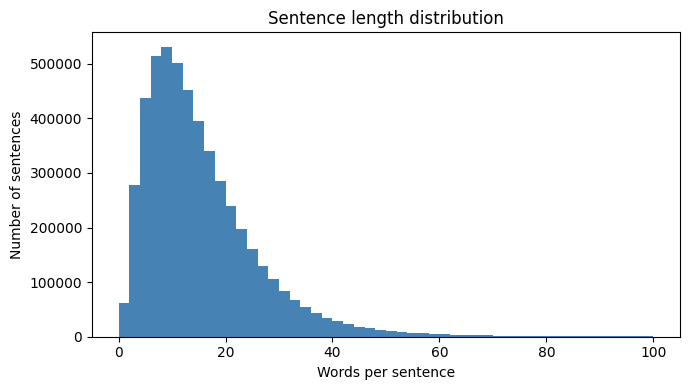

In [23]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

OUT_DIR = Path("/kaggle/working/processed_full")        # full run: processed_full
PAD, UNK, BOS, EOS = 0, 1, 2, 3

vocab = (OUT_DIR / "vocab.txt").read_text(encoding="utf-8").split("\n")
stats = json.loads((OUT_DIR / "stats.json").read_text(encoding="utf-8"))
data = {s: np.load(OUT_DIR / f"{s}.npy") for s in ("train", "dev", "test")}
num_ids = np.array([i for i, w in enumerate(vocab) if "<NUM>" in w], dtype=np.int64)

lines = []
def out(s=""):
    print(s)
    lines.append(s)

# ---- Table 1: split overview ----
out("### Table 1: Corpus after preprocessing")
out("| Split | Sentences | Tokens | Avg. length | `<UNK>` % | `<NUM>` tokens % |")
out("|---|---:|---:|---:|---:|---:|")
lengths, counts = {}, {}
for s, arr in data.items():
    ends = np.flatnonzero(arr == EOS)
    starts = np.flatnonzero(arr == BOS)
    lengths[s] = ends - starts - 1
    counts[s] = np.bincount(arr, minlength=len(vocab))
    tokens = int(lengths[s].sum())
    if len(ends) == 0 or tokens == 0:
        out(f"| {s} | {len(ends):,} | {tokens:,} | empty split | n/a | n/a |")
        continue
    out(f"| {s} | {len(ends):,} | {tokens:,} | {tokens / len(ends):.1f} "
        f"| {100 * counts[s][UNK] / tokens:.2f} | {100 * counts[s][num_ids].sum() / tokens:.2f} |")

# ---- Table 2: vocabulary coverage (train) ----
total = int(lengths["train"].sum())
word_counts = np.sort(counts["train"][4:])[::-1]
cum = np.cumsum(word_counts)
out()
out("### Table 2: Share of train tokens covered by the top-k vocabulary words")
if total == 0 or len(cum) == 0:
    out("The train split has no tokens, so coverage cannot be computed.")
else:
    out("| Top-k words | Coverage % |")
    out("|---:|---:|")
    for k in (100, 1_000, 5_000, 10_000, 20_000, len(word_counts)):
        k = min(k, len(cum))
        out(f"| {k:,} | {100 * cum[k - 1] / total:.2f} |")

# ---- Table 3: top 20 tokens ----
out()
out("### Table 3: 20 most frequent tokens (train)")
if len(word_counts) == 0:
    out("The train split has no tokens.")
else:
    out("| Rank | Token | Count |")
    out("|---:|---|---:|")
    for r, i in enumerate(np.argsort(counts["train"][4:])[::-1][:20] + 4, 1):
        out(f"| {r} | {vocab[i]} | {counts['train'][i]:,} |")

# ---- Table 4: sentence length ----
allen = np.concatenate(list(lengths.values()))
out()
out("### Table 4: Sentence length (words, after cleaning)")
if allen.size == 0:
    out("No sentences in any split.")
else:
    out("| Mean | Median | 90th pct | 99th pct | Max |")
    out("|---:|---:|---:|---:|---:|")
    out(f"| {allen.mean():.1f} | {np.median(allen):.0f} | {np.percentile(allen, 90):.0f} "
        f"| {np.percentile(allen, 99):.0f} | {allen.max()} |")

# ---- Table 5: preprocessing outcome ----
out()
out("### Table 5: Preprocessing outcome")
out("| Item | Value |")
out("|---|---:|")
rows = [
    ("Rules version", stats["version"]),
    ("Sample fraction", stats["sample_fraction"]),
    ("Sample seed / split seed", f"{stats['seeds']['sample']} / {stats['seeds']['split']}"),
    ("Sentence pieces in the corpus", f"{stats['corpus']['pieces_total']:,}"),
    ("Words in the raw corpus (whitespace-separated)", f"{stats['corpus']['raw_words_total']:,}"),
    ("Sentences sampled", f"{stats['corpus']['pieces_sampled']:,}"),
    (f"Sentences dropped (over {stats['rules']['max_tokens_per_sentence']} tokens)", f"{stats['dropped_too_long']:,}"),
    ("Tokens discarded by that cutoff", f"{stats['tokens_discarded']:,} ({stats['tokens_discarded_percent']}%)"),
    ("Empty after cleaning", f"{stats['empty_after_tokenize']:,}"),
    ("Repeated sentences (train / dev / test)", " / ".join(f"{stats['duplicate_sentences'][s]:,}" for s in ("train", "dev", "test"))),
    ("Vocabulary size", f"{stats['vocab']['size']:,}"),
    ("Unique words (train / all splits)", f"{stats['vocab']['unique_words_train']:,} / {stats['vocab']['unique_words_total']:,}"),
    ("`<UNK>` rate % (train / dev / test)", " / ".join(str(stats['unk_rate_percent'][s]) for s in ("train", "dev", "test"))),
]
for name, value in rows:
    out(f"| {name} | {value} |")

# ---- Table 6: before and after normalization ----
out()
out("### Table 6: Before and after normalization")
examples = stats.get("normalization_examples", [])
if not examples:
    out("No normalization examples in stats.json (re-run Cell 3 and Cell 5).")
else:
    out("| Raw | Tokens |")
    out("|---|---|")
    for ex in examples:
        out(f"| {ex['raw']} | {' '.join(ex['tokens'])} |")

(OUT_DIR / "report_tables.md").write_text("\n".join(lines), encoding="utf-8")

if allen.size:
    plt.figure(figsize=(7, 4))
    plt.hist(allen, bins=range(0, 101, 2), color="steelblue")
    plt.xlabel("Words per sentence")
    plt.ylabel("Number of sentences")
    plt.title("Sentence length distribution")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "sentence_lengths.png", dpi=150)
    print("\nSaved report_tables.md and sentence_lengths.png")
else:
    print("\nSaved report_tables.md (no histogram: no sentences)")

In [24]:
import json, sys
import numpy as np
from pathlib import Path
sys.path.insert(0, "/kaggle/working")
import importlib, preprocess_lib
importlib.reload(preprocess_lib)
from preprocess_lib import normalize, tokenize, RULES_VERSION, MERGE_FOURTH_ORDER_HA, SAMPLE_SEED, SPLIT_SEED
from preprocess import validate_output

OUT_DIR = Path("/kaggle/working/processed_full")   # processed_sample for the 5% sample
EXPECTED_SAMPLE = 1.0                               # 0.05 for the 5% sample

vocab, stats = validate_output(OUT_DIR)             # special IDs, <=50k, train-only vocab, paired <s></s>, int32

# duplicates must not cross splits (only sentences without <UNK>)
sets = {}
for s in ("train", "dev", "test"):
    arr = np.load(OUT_DIR / f"{s}.npy")
    st, en = np.flatnonzero(arr == 2), np.flatnonzero(arr == 3)
    sets[s] = {arr[a+1:b].tobytes() for a, b in zip(st, en) if not (arr[a+1:b] == 1).any()}
no_cross = all(not (sets[x] & sets[y]) for x, y in (("train","dev"),("train","test"),("dev","test")))

variants = {chr(k) for k in preprocess_lib._VARIANTS}  # every character that must have been rewritten
checks = [
 ("1 Variants merged incl. 4th order",   MERGE_FOURTH_ORDER_HA and all(normalize(c) == "ሀ" for c in "ሀሃሓኃ")),
 ("1 No variant letter left in vocab",   not any(ch in w for w in vocab[4:] for ch in variants)),
 ("1 Stats record the spelling rule",    "ሃ ሓ ኃ -> ሀ" in stats["rules"]["spelling"]),
 ("1/2 Same tokenizer for train+predict", tokenize("በ1980 ዓ.ም ሃገር") == tokenize(" ".join(tokenize("በ1980 ዓ.ም ሃገር")))),
 ("2 <NUM> and <NUM>ኛ in vocab",         "<NUM>" in vocab and "<NUM>ኛ" in vocab),
 ("3 Sample fraction + seed recorded",   stats["sample_fraction"] == EXPECTED_SAMPLE and stats["seeds"]["sample"] == SAMPLE_SEED),
 ("4 Split seed recorded",               stats["seeds"]["split"] == SPLIT_SEED),
 ("4 No sentence in two splits",         no_cross),
 ("5 Vocab <= 50,000, specials 0-3",     len(vocab) <= 50_000 and vocab[:4] == ["<PAD>","<UNK>","<s>","</s>"]),
 ("5 UNK rates recorded (all splits)",   set(stats["unk_rate_percent"]) == {"train","dev","test"}),
 ("6 Dropped count + tokens discarded",  "dropped_too_long" in stats and "tokens_discarded" in stats),
 ("6 longest_50.txt exists",             (OUT_DIR / "longest_50.txt").exists()),
 ("8 Rules version recorded",            stats["version"] == RULES_VERSION),
]
for name, ok in checks:
    print("PASS" if ok else "FAIL", "|", name)
assert all(ok for _, ok in checks), "fix the FAIL lines"

PASS | 1 Variants merged incl. 4th order
PASS | 1 No variant letter left in vocab
PASS | 1 Stats record the spelling rule
PASS | 1/2 Same tokenizer for train+predict
PASS | 2 <NUM> and <NUM>ኛ in vocab
PASS | 3 Sample fraction + seed recorded
PASS | 4 Split seed recorded
PASS | 4 No sentence in two splits
PASS | 5 Vocab <= 50,000, specials 0-3
PASS | 5 UNK rates recorded (all splits)
PASS | 6 Dropped count + tokens discarded
PASS | 6 longest_50.txt exists
PASS | 8 Rules version recorded
